# Infrastructure Optimization and Power Aware Scheduling

This notebook extends the GenAI workload power prediction model into a simulated infrastructure decision layer.

The goal is to evaluate whether predicted workload power can support power aware scheduling and capacity planning decisions under hypothetical infrastructure constraints.

The scheduling results in this notebook are simulations and do not represent actual NLR production scheduling decisions or measured infrastructure savings.

## Load the Trained Model and Generate Power Predictions

This notebook builds on the model developed in `03_Modeling.ipynb`. Instead of retraining the model, we load the saved XGBoost model and the held out test data from Google Drive.

The model predicts execution level mean power for each workload configuration. These predictions will be used as the input to the decision layer, where we will evaluate how power aware scheduling could support infrastructure capacity planning.

The actual power values are retained only for evaluating the quality of the simulated scheduling decisions. The scheduler itself will make decisions using predicted power rather than observed power.

In [48]:
# Mount the drive so that best model can be chosen from the saved mounted drive
from google.colab import drive

drive.mount("/content/drive")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [49]:
from pathlib import Path
import joblib
import pandas as pd
# Paths to the persisted modeling artifacts.
processed_dir = Path("/content/drive/MyDrive/data/processed/modeling")
model_path = processed_dir / "best_model.joblib"
if not model_path.exists():
    raise FileNotFoundError(f"Trained model not found: {model_path}")
# Load the selected model artifact created in 03_Modeling.ipynb.
model_artifact = joblib.load(model_path)
best_model = model_artifact["model"]
feature_names = model_artifact["feature_names"]
# Load the held out test data used for model evaluation.
X_test = pd.read_parquet(processed_dir / "X_test.parquet")
y_test = pd.read_parquet(processed_dir / "y_test.parquet")["mean_power_w"]
test_raw = pd.read_parquet(processed_dir / "test_raw.parquet")
print(f"Loaded model: {type(best_model).__name__}")
print(f"Test records: {len(X_test):,}")
print(f"Features: {len(feature_names)}")

Loaded model: XGBRegressor
Test records: 364
Features: 14


In [50]:
# Check that the test data matches the feature schema used by the trained model.
if list(X_test.columns) != feature_names:
    raise ValueError("Test feature columns do not match the saved model feature names.")
print("Model and test features are aligned.")
print(f"Model: {type(best_model).__name__}")
print(f"Test records: {len(X_test):,}")

Model and test features are aligned.
Model: XGBRegressor
Test records: 364


In [51]:
# Prediction Layer
# Generate predicted execution level mean power.
predicted_power_w = best_model.predict(X_test)
prediction_results = test_raw.copy()
prediction_results["actual_power_w"] = y_test.values
prediction_results["predicted_power_w"] = predicted_power_w
prediction_results[
    ["workload_type", "actual_power_w", "predicted_power_w"]
].head(10)

,workload_type,actual_power_w,predicted_power_w
2186,online_finite_inference,2256.377925,2252.322510
1793,online_finite_inference,2625.840706,2600.139404
1272,online_finite_inference,2541.145137,2547.630859
1775,online_finite_inference,2552.795470,2582.927490
1822,online_finite_inference,2551.016595,2539.693848
579,offline_inference,2129.736377,2112.913086
1684,online_finite_inference,2622.444863,2567.202637
1757,online_finite_inference,2476.994837,2468.953125
112,offline_inference,2690.920602,2673.919678
2231,online_rate_inference,2215.768588,2178.286621


In [52]:
print("Prediction summary:")
print(f"Mean predicted power: {predicted_power_w.mean():.2f} W")
print(f"Minimum predicted power: {predicted_power_w.min():.2f} W")
print(f"Maximum predicted power: {predicted_power_w.max():.2f} W")

Prediction summary:
Mean predicted power: 2594.67 W
Minimum predicted power: 2017.77 W
Maximum predicted power: 2897.95 W


## Define Infrastructure Constraints

To evaluate the model as a decision support tool, we simulate a data center environment with a fixed power budget and a limited number of available execution slots.

These constraints are hypothetical and are used to test whether predicted workload power can be incorporated into scheduling decisions. The values are not intended to represent the actual power capacity or scheduling policy of the NLR infrastructure.

In [53]:
# Define hypothetical infrastructure constraints for the scheduling simulation.
POWER_BUDGET_W = 10_000
AVAILABLE_SLOTS = 4
print(f"Power budget: {POWER_BUDGET_W:,} W")
print(f"Available execution slots: {AVAILABLE_SLOTS}")

Power budget: 10,000 W
Available execution slots: 4


## Prepare Candidate Workloads

The scheduler needs a set of candidate workload executions to evaluate. We use the test set predictions generated above so that each candidate has an estimated power requirement.

The scheduler will use these predicted values to determine which workloads can be placed within the available power budget and execution capacity.

In [54]:
#Prepare candidate workloads for the scheduling simulation.
candidate_workloads = prediction_results[
    [
        "workload_type",
        "predicted_power_w",
        "actual_power_w",
    ]
].copy()
candidate_workloads["predicted_power_w"] = (
    candidate_workloads["predicted_power_w"].round(2)
)
candidate_workloads.head()

,workload_type,predicted_power_w,actual_power_w
2186,online_finite_inference,2252.320068,2256.377925
1793,online_finite_inference,2600.139893,2625.840706
1272,online_finite_inference,2547.629883,2541.145137
1775,online_finite_inference,2582.929932,2552.795470
1822,online_finite_inference,2539.689941,2551.016595


## Implement the Power Aware Scheduling Decision

The scheduler evaluates candidate workloads using their predicted power requirements, the available execution slots, and the infrastructure power budget.

For this initial simulation, a workload is scheduled only when adding its predicted power would keep the total scheduled power within the defined budget and an execution slot is available.

This is a deterministic scheduling rule used to demonstrate how the ML predictions can support an infrastructure decision. It is not intended to represent a production scheduling algorithm.

## Establish a Baseline Scheduler

To measure the value of power aware scheduling, we need a simple baseline for comparison.

The baseline represents a scheduler that fills available execution slots without considering predicted power consumption. Its scheduled power is then evaluated against the same infrastructure power budget.

Comparing the two approaches allows us to quantify whether incorporating ML based power predictions improves power budget compliance and infrastructure utilization.

In [55]:
# Baseline: schedule the first available workloads without considering power.
baseline_workloads = candidate_workloads.head(AVAILABLE_SLOTS).copy()
baseline_predicted_power_w = baseline_workloads["predicted_power_w"].sum()
print(f"Baseline workloads scheduled: {len(baseline_workloads)}")
print(f"Baseline predicted power: {baseline_predicted_power_w:,.2f} W")
print(
    f"Power budget exceeded: "
    f"{baseline_predicted_power_w > POWER_BUDGET_W}"
)

Baseline workloads scheduled: 4
Baseline predicted power: 9,983.02 W
Power budget exceeded: False


## Create a Scheduling Batch

A meaningful scheduling comparison requires more candidate workloads than available execution slots.

We use a batch of candidate executions from the test set and allow the scheduler to select up to four workloads. This creates a decision scenario where multiple workload combinations are possible under the same power constraint.

The baseline will follow a first come, first served strategy, while the power aware scheduler will use predicted power to make its selection.

In [56]:
# Use a larger candidate batch so the scheduler has multiple choices.
SCHEDULING_BATCH_SIZE = len(candidate_workloads)   # use full test set
scheduling_batch = candidate_workloads.head(SCHEDULING_BATCH_SIZE).copy()
print(f"Candidate workloads: {len(scheduling_batch)}")
print(f"Available execution slots: {AVAILABLE_SLOTS}")
print(f"Power budget: {POWER_BUDGET_W:,} W")

Candidate workloads: 364
Available execution slots: 4
Power budget: 10,000 W


## Run the Power Aware Scheduling Strategy

The scheduler now evaluates multiple candidate workloads rather than processing only the first available executions.

At each scheduling step, it selects the candidate with the lowest predicted power that can fit within the remaining power budget. This provides a simple and transparent power aware strategy for the initial simulation.

The objective is to demonstrate how ML based power predictions can influence workload placement while respecting both infrastructure capacity and power constraints.

In [57]:
def power_aware_schedule(
    workloads,
    power_budget_w,
    available_slots,
    safety_margin_w=0,
):
    """
    Greedy, lowest predicted power first scheduler.
    NOTE: This is one simple heuristic, not a proven optimal scheduling
    policy,it prioritizes minimizing scheduled power over maximizing
    throughput/utilization. safety_margin_w reserves headroom against
    prediction error (e.g. set it to the model's test MAE from
    03_Modeling.ipynb) so the *actual* power is less likely to exceed
    the budget even though the decision is made on *predicted* power.
    """
    remaining = workloads.copy()
    scheduled_indices = []
    total_predicted_power_w = 0.0
    effective_budget_w = power_budget_w - safety_margin_w
    while (
        len(scheduled_indices) < available_slots
        and not remaining.empty
    ):
        # Keep only workloads that fit within the remaining (margin adjusted) budget.
        feasible = remaining[
            total_predicted_power_w + remaining["predicted_power_w"]
            <= effective_budget_w
        ]
        if feasible.empty:
            break
        # Select the lowest power feasible workload.
        selected_index = feasible["predicted_power_w"].idxmin()
        selected_power = remaining.loc[
            selected_index, "predicted_power_w"
        ]
        scheduled_indices.append(selected_index)
        total_predicted_power_w += selected_power
        remaining = remaining.drop(index=selected_index)
    return scheduled_indices, total_predicted_power_w
# Reserve a safety margin roughly equal to the model's test MAE (~25W, from 03_Modeling.ipynb)
SAFETY_MARGIN_W = 25
power_aware_indices, power_aware_power_w = power_aware_schedule(
    scheduling_batch,
    POWER_BUDGET_W,
    AVAILABLE_SLOTS,
    safety_margin_w=SAFETY_MARGIN_W,
)
print(f"Power aware workloads scheduled: {len(power_aware_indices)}")
print(f"Predicted scheduled power: {power_aware_power_w:,.2f} W")
print(f"Safety margin reserved: {SAFETY_MARGIN_W:,.2f} W")
print(
    f"Remaining power capacity: "
    f"{POWER_BUDGET_W - power_aware_power_w:,.2f} W"
)

Power aware workloads scheduled: 4
Predicted scheduled power: 8,071.08 W
Safety margin reserved: 25.00 W
Remaining power capacity: 1,928.92 W


## Compare Scheduling Strategies

The power aware scheduler selects workloads using predicted power, while the baseline follows a first come, first served strategy.

We compare both approaches using the same candidate batch and infrastructure constraints. After scheduling, the actual measured power is used only to evaluate how well each strategy performed against the power budget.

This allows us to quantify the practical value of incorporating ML based power predictions into infrastructure scheduling decisions.

In [58]:
# First come, first served baseline.
baseline_indices = scheduling_batch.head(AVAILABLE_SLOTS).index
baseline_selected = scheduling_batch.loc[baseline_indices]
baseline_predicted_power_w = baseline_selected["predicted_power_w"].sum()
baseline_actual_power_w = baseline_selected["actual_power_w"].sum()
print(f"Baseline workloads scheduled: {len(baseline_selected)}")
print(f"Baseline predicted power: {baseline_predicted_power_w:,.2f} W")
print(f"Baseline actual power: {baseline_actual_power_w:,.2f} W")

Baseline workloads scheduled: 4
Baseline predicted power: 9,983.02 W
Baseline actual power: 9,976.16 W


## Evaluate the Power Aware Schedule

The scheduler made its decision using predicted power only. We now evaluate the selected workloads using their actual measured power from the test dataset.

This separation is important: actual power is not used to make the scheduling decision. It is used only after scheduling to determine whether the prediction driven decision stayed within the simulated infrastructure constraints.

In [59]:
power_aware_selected = scheduling_batch.loc[power_aware_indices]
power_aware_actual_power_w = (
    power_aware_selected["actual_power_w"].sum()
)
print(f"Power aware workloads scheduled: {len(power_aware_selected)}")
print(f"Predicted power: {power_aware_power_w:,.2f} W")
print(f"Actual power: {power_aware_actual_power_w:,.2f} W")
print(
    f"Actual remaining capacity: "
    f"{POWER_BUDGET_W - power_aware_actual_power_w:,.2f} W"
)

Power aware workloads scheduled: 4
Predicted power: 8,071.08 W
Actual power: 8,089.16 W
Actual remaining capacity: 1,910.84 W


## Quantify Scheduling Performance

We compare the baseline and power aware strategies using the same infrastructure constraints.

The key measures are scheduled workload count, actual power consumption, power budget utilization, remaining capacity, and whether the schedule exceeded the available power budget.

These metrics provide a direct measure of how the prediction model can support a measurable infrastructure decision.

In [60]:
baseline_utilization = (
    baseline_actual_power_w / POWER_BUDGET_W
)
power_aware_utilization = (
    power_aware_actual_power_w / POWER_BUDGET_W
)
scheduling_comparison = pd.DataFrame([
    {
        "strategy": "FCFS baseline",
        "workloads_scheduled": len(baseline_selected),
        "actual_power_w": baseline_actual_power_w,
        "power_utilization": baseline_utilization,
        "remaining_capacity_w": POWER_BUDGET_W - baseline_actual_power_w,
        "budget_violation": baseline_actual_power_w > POWER_BUDGET_W,
    },
    {
        "strategy": "Power-aware",
        "workloads_scheduled": len(power_aware_selected),
        "actual_power_w": power_aware_actual_power_w,
        "power_utilization": power_aware_utilization,
        "remaining_capacity_w": POWER_BUDGET_W - power_aware_actual_power_w,
        "budget_violation": power_aware_actual_power_w > POWER_BUDGET_W,
    },
])
display(scheduling_comparison)

,strategy,workloads_scheduled,actual_power_w,power_utilization,remaining_capacity_w,budget_violation
0,FCFS baseline,4,9976.159238,0.997616,23.840762,False
1,Power-aware,4,8089.163473,0.808916,1910.836527,False


## Measure the Infrastructure Improvement

The power aware scheduler achieved the same number of scheduled workloads while using less power than the FCFS baseline.

We calculate the relative reduction in actual power consumption and the additional power capacity made available by the power aware strategy.

In [61]:
#Calculate improvement
power_reduction_w = (
    baseline_actual_power_w - power_aware_actual_power_w
)
power_reduction_pct = (
    power_reduction_w / baseline_actual_power_w * 100
)
additional_headroom_w = (
    (POWER_BUDGET_W - power_aware_actual_power_w)
    - (POWER_BUDGET_W - baseline_actual_power_w)
)
print(f"Power reduction: {power_reduction_w:,.2f} W")
print(f"Relative power reduction: {power_reduction_pct:.2f}%")
print(f"Additional power headroom: {additional_headroom_w:,.2f} W")

Power reduction: 1,887.00 W
Relative power reduction: 18.92%
Additional power headroom: 1,887.00 W


## Visualize the Scheduling Comparison

The following comparison shows how the two scheduling strategies use the same 10 kW simulated power budget.

The visualization highlights the reduction in actual power consumption achieved by the power aware strategy while maintaining the same number of scheduled workloads.

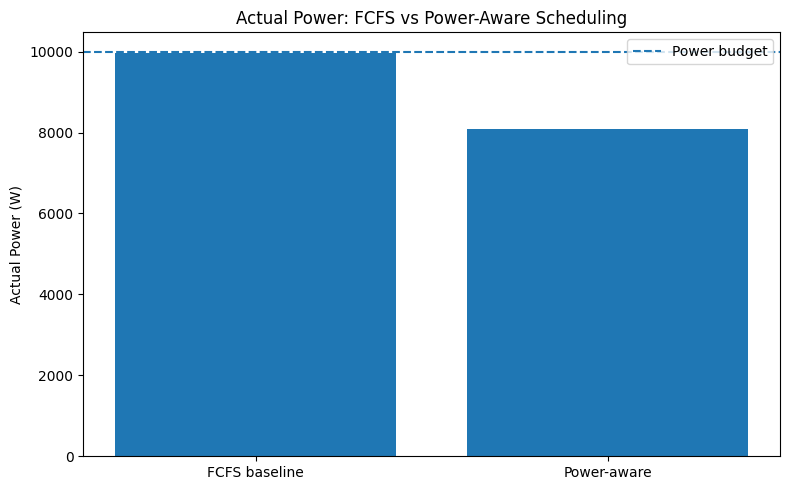

In [62]:
import matplotlib.pyplot as plt
plt.figure(figsize=(8, 5))
plt.bar(
    scheduling_comparison["strategy"],
    scheduling_comparison["actual_power_w"],
)

plt.axhline(
    POWER_BUDGET_W,
    linestyle="--",
    label="Power budget",
)

plt.ylabel("Actual Power (W)")
plt.title("Actual Power: FCFS vs Power-Aware Scheduling")
plt.legend()
plt.tight_layout()
plt.show()

## Evaluate Scheduling Across Multiple Power Budgets

A single power budget provides only one scheduling scenario. To make the comparison more robust, we evaluate both scheduling strategies across multiple hypothetical infrastructure power budgets.

The candidate workloads, execution slot limit, and scheduling rules remain unchanged. Only the available power budget varies.

For each budget, the baseline follows the first come, first served strategy, while the power aware scheduler selects workloads using predicted power. Actual measured power is used only after scheduling to evaluate the resulting decisions.

This experiment shows whether the observed scheduling improvement remains consistent across different infrastructure capacity constraints.

In [63]:
POWER_BUDGETS_W = [
    8_000,
    9_000,
    10_000,
    11_000,
    12_000,
]
multi_budget_results = []
for power_budget_w in POWER_BUDGETS_W:
    # FCFS baseline
    baseline_indices = scheduling_batch.head(AVAILABLE_SLOTS).index
    baseline_selected = scheduling_batch.loc[baseline_indices]
    baseline_predicted_power_w = (
        baseline_selected["predicted_power_w"].sum()
    )
    baseline_actual_power_w = (
        baseline_selected["actual_power_w"].sum()
    )
    # Power aware strategy
    power_aware_indices, power_aware_predicted_power_w = (
        power_aware_schedule(
            scheduling_batch,
            power_budget_w,
            AVAILABLE_SLOTS,
            safety_margin_w=SAFETY_MARGIN_W,
        )
    )
    power_aware_selected = scheduling_batch.loc[power_aware_indices]
    power_aware_actual_power_w = (
        power_aware_selected["actual_power_w"].sum()
    )
    # Store results for both strategies
    multi_budget_results.extend([
        {
            "power_budget_w": power_budget_w,
            "strategy": "FCFS baseline",
            "workloads_scheduled": len(baseline_selected),
            "predicted_power_w": baseline_predicted_power_w,
            "actual_power_w": baseline_actual_power_w,
            "power_utilization": (
                baseline_actual_power_w / power_budget_w
            ),
            "budget_violation": (
                baseline_actual_power_w > power_budget_w
            ),
        },
        {
            "power_budget_w": power_budget_w,
            "strategy": "Power-aware",
            "workloads_scheduled": len(power_aware_selected),
            "predicted_power_w": power_aware_predicted_power_w,
            "actual_power_w": power_aware_actual_power_w,
            "power_utilization": (
                power_aware_actual_power_w / power_budget_w
            ),
            "budget_violation": (
                power_aware_actual_power_w > power_budget_w
            ),
        },
    ])
multi_budget_comparison = pd.DataFrame(multi_budget_results)
display(multi_budget_comparison)

,power_budget_w,strategy,workloads_scheduled,predicted_power_w,actual_power_w,power_utilization,budget_violation
0,8000,FCFS baseline,4,9983.019531,9976.159238,1.247020,True
1,8000,Power-aware,3,6053.310059,6077.111857,0.759639,False
2,9000,FCFS baseline,4,9983.019531,9976.159238,1.108462,True
3,9000,Power-aware,4,8071.080078,8089.163473,0.898796,False
4,10000,FCFS baseline,4,9983.019531,9976.159238,0.997616,False
5,10000,Power-aware,4,8071.080078,8089.163473,0.808916,False
6,11000,FCFS baseline,4,9983.019531,9976.159238,0.906924,False
7,11000,Power-aware,4,8071.080078,8089.163473,0.735378,False
8,12000,FCFS baseline,4,9983.019531,9976.159238,0.831347,False
9,12000,Power-aware,4,8071.080078,8089.163473,0.674097,False


## Quantify Improvement Across Power Budgets

The multi budget experiment allows us to evaluate whether the scheduling benefit is consistent across different infrastructure constraints.

For each power budget, we calculate the actual remaining power capacity and the difference in actual power consumption between the FCFS baseline and the power aware strategy.

These results are used to determine whether power aware scheduling can reduce power consumption or prevent budget violations while maintaining as many scheduled workloads as possible.

In [64]:
budget_summary = (
    multi_budget_comparison
    .pivot(
        index="power_budget_w",
        columns="strategy",
        values=[
            "workloads_scheduled",
            "actual_power_w",
            "power_utilization",
            "budget_violation",
        ],
    )
)

budget_summary.columns = [
    f"{metric}_{strategy.replace(' ', '_').replace('-', '_').lower()}"
    for metric, strategy in budget_summary.columns
]

budget_summary = budget_summary.reset_index()

budget_summary["fcfs_headroom_w"] = (
    budget_summary["power_budget_w"]
    - budget_summary["actual_power_w_fcfs_baseline"]
)

budget_summary["power_aware_headroom_w"] = (
    budget_summary["power_budget_w"]
    - budget_summary["actual_power_w_power_aware"]
)

budget_summary["power_reduction_w"] = (
    budget_summary["actual_power_w_fcfs_baseline"]
    - budget_summary["actual_power_w_power_aware"]
)

budget_summary["power_reduction_pct"] = (
    budget_summary["power_reduction_w"]
    / budget_summary["actual_power_w_fcfs_baseline"]
    * 100
)

display(
    budget_summary[
        [
            "power_budget_w",
            "workloads_scheduled_fcfs_baseline",
            "workloads_scheduled_power_aware",
            "actual_power_w_fcfs_baseline",
            "actual_power_w_power_aware",
            "fcfs_headroom_w",
            "power_aware_headroom_w",
            "power_reduction_w",
            "power_reduction_pct",
            "budget_violation_fcfs_baseline",
            "budget_violation_power_aware",
        ]
    ]
)

,power_budget_w,workloads_scheduled_fcfs_baseline,workloads_scheduled_power_aware,actual_power_w_fcfs_baseline,actual_power_w_power_aware,fcfs_headroom_w,power_aware_headroom_w,power_reduction_w,power_reduction_pct,budget_violation_fcfs_baseline,budget_violation_power_aware
0,8000,4,3,9976.159238,6077.111857,-1976.159238,1922.888143,3899.047381,39.083652,True,False
1,9000,4,4,9976.159238,8089.163473,-976.159238,910.836527,1886.995765,18.915053,True,False
2,10000,4,4,9976.159238,8089.163473,23.840762,1910.836527,1886.995765,18.915053,False,False
3,11000,4,4,9976.159238,8089.163473,1023.840762,2910.836527,1886.995765,18.915053,False,False
4,12000,4,4,9976.159238,8089.163473,2023.840762,3910.836527,1886.995765,18.915053,False,False


## Visualize Power Budget Utilization

The following visualization compares power budget utilization for the FCFS baseline and power aware scheduling strategies across multiple hypothetical infrastructure power budgets.

A utilization above 100% indicates that the schedule exceeded the available power budget. The comparison shows how predicted power can help the scheduler remain within tighter infrastructure constraints while maintaining workload capacity when feasible.

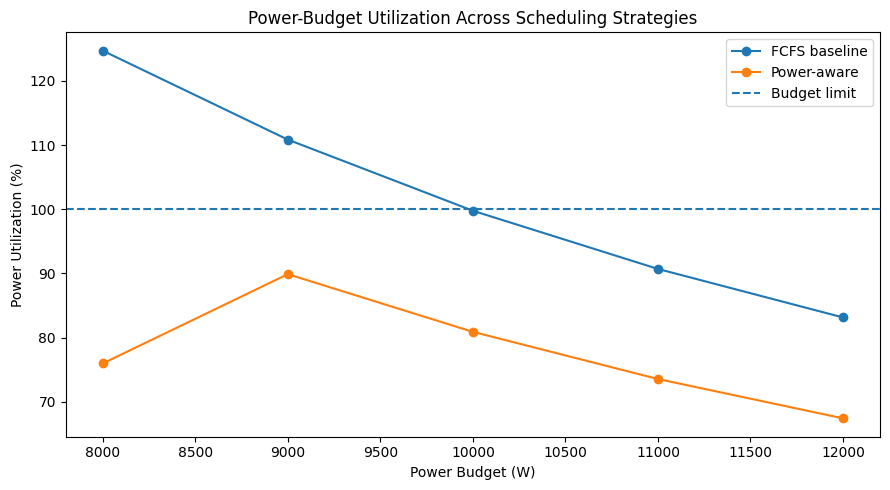

In [65]:
import matplotlib.pyplot as plt
plt.figure(figsize=(9, 5))
for strategy in ["FCFS baseline", "Power-aware"]:
    strategy_data = multi_budget_comparison[
        multi_budget_comparison["strategy"] == strategy
    ]
    plt.plot(
        strategy_data["power_budget_w"],
        strategy_data["power_utilization"] * 100,
        marker="o",
        label=strategy,
    )
plt.axhline(
    100,
    linestyle="--",
    label="Budget limit",
)
plt.xlabel("Power Budget (W)")
plt.ylabel("Power Utilization (%)")
plt.title("Power-Budget Utilization Across Scheduling Strategies")
plt.legend()
plt.tight_layout()
plt.show()

In [66]:
# Create clean column names for easier downstream analysis.
budget_summary = budget_summary.rename(
    columns={
        "workloads_scheduled_fcfs_baseline": "fcfs_workloads",
        "workloads_scheduled_power_aware": "power_aware_workloads",
        "actual_power_w_fcfs_baseline": "fcfs_actual_power_w",
        "actual_power_w_power_aware": "power_aware_actual_power_w",
        "budget_violation_fcfs_baseline": "fcfs_budget_violation",
        "budget_violation_power_aware": "power_aware_budget_violation",
    }
)

# Find the maximum power reduction when both strategies
# schedule the same number of workloads.
equal_workload_results = budget_summary[
    budget_summary["fcfs_workloads"]
    == budget_summary["power_aware_workloads"]
]

max_equal_workload_reduction = (
    equal_workload_results["power_reduction_pct"].max()
)

# Retrieve the 8 kW, 9 kW, and 10 kW scenarios.
eight_kw_result = budget_summary[
    budget_summary["power_budget_w"] == 8_000
].iloc[0]

nine_kw_result = budget_summary[
    budget_summary["power_budget_w"] == 9_000
].iloc[0]

ten_kw_result = budget_summary[
    budget_summary["power_budget_w"] == 10_000
].iloc[0]

print("Infrastructure Optimization Summary")
print("-" * 40)

print(
    f"Across the full 364 execution test set, at 9 kW, "
    f"power aware scheduling selected "
    f"{int(nine_kw_result['power_aware_workloads'])} workloads "
    f"without exceeding the power budget, while FCFS exceeded the budget."
)

print(
    f"At 8 kW, power aware scheduling selected "
    f"{int(eight_kw_result['power_aware_workloads'])} workloads "
    f"compared with {int(eight_kw_result['fcfs_workloads'])} for FCFS "
    f"while remaining within the power constraint."
)

print(
    f"When both strategies selected the same number of workloads, "
    f"the maximum observed reduction in actual scheduled power was "
    f"{max_equal_workload_reduction:.2f}%."
)

print(
    f"At the 10 kW budget, power-aware scheduling provided "
    f"{ten_kw_result['power_aware_headroom_w']:,.0f} W "
    f"of remaining capacity compared with "
    f"{ten_kw_result['fcfs_headroom_w']:,.0f} W for FCFS."
)

Infrastructure Optimization Summary
----------------------------------------
Across the full 364 execution test set, at 9 kW, power aware scheduling selected 4 workloads without exceeding the power budget, while FCFS exceeded the budget.
At 8 kW, power aware scheduling selected 3 workloads compared with 4 for FCFS while remaining within the power constraint.
When both strategies selected the same number of workloads, the maximum observed reduction in actual scheduled power was 18.92%.
At the 10 kW budget, power-aware scheduling provided 1,911 W of remaining capacity compared with 24 W for FCFS.


## Conclusion

This simulation demonstrates how execution level power predictions can be incorporated into a simple infrastructure scheduling decision.

Across the tested hypothetical power budgets, the power aware strategy avoided budget violations under tighter constraints and reduced actual scheduled power when the same number of workloads could be accommodated. At the 10 kW budget, for example, the strategy scheduled the same four workloads while leaving approximately 1.91 kW of additional power headroom compared with the FCFS baseline.

These findings demonstrate the potential of the ML model to support power aware capacity planning and workload scheduling. The results are simulation-based and should not be interpreted as measured production savings or an optimal scheduling policy.

## For my understanding if I want to change and move towards agentic scheduler I need these artifacts

In [68]:
from pathlib import Path
import json
# Create the optimization artifact directory.
optimization_dir = Path(
    "/content/drive/MyDrive/data/processed/optimization"
)
optimization_dir.mkdir(parents=True, exist_ok=True)
# Save all 364 test executions with predicted and actual power.
prediction_results.to_parquet(
    optimization_dir / "test_predictions.parquet",
    index=False,
)
# Save the multi budget scheduling results.
budget_summary.to_parquet(
    optimization_dir / "budget_summary.parquet",
    index=False,
)
# Save the configuration used for the simulation.
optimization_config = {
    "test_set_size": len(prediction_results),
    "available_slots": AVAILABLE_SLOTS,
    "power_budgets_w": POWER_BUDGETS_W,
    "safety_margin_w": SAFETY_MARGIN_W,
    "baseline_strategy": "FCFS",
    "scheduler_type": "greedy_lowest_predicted_power",
    "prediction_target": "mean_power_w",
    "decision_field": "predicted_power_w",
    "evaluation_field": "actual_power_w",
    "simulation_only": True,
}
with open(
    optimization_dir / "optimization_config.json",
    "w",
    encoding="utf-8",
) as file:
    json.dump(
        optimization_config,
        file,
        indent=2,
    )
# Save the deterministic power aware scheduler.
scheduler_code = '''def power_aware_schedule(
    workloads,
    power_budget_w,
    available_slots,
    safety_margin_w=0,
):
    """
    Greedy power-aware scheduling baseline.

    Selects the feasible workload with the lowest predicted
    power until the available execution slots or effective
    power budget is reached.

    The safety margin provides a conservative planning buffer
    for prediction error; it does not provide a statistical
    guarantee.
    """
    remaining = workloads.copy()
    scheduled_indices = []
    total_predicted_power_w = 0.0
    effective_budget_w = power_budget_w - safety_margin_w
    while (
        len(scheduled_indices) < available_slots
        and not remaining.empty
    ):
        feasible = remaining[
            total_predicted_power_w
            + remaining["predicted_power_w"]
            <= effective_budget_w
        ]
        if feasible.empty:
            break
        selected_index = feasible["predicted_power_w"].idxmin()
        selected_power = remaining.loc[
            selected_index,
            "predicted_power_w",
        ]
        scheduled_indices.append(selected_index)
        total_predicted_power_w += selected_power
        remaining = remaining.drop(index=selected_index)
    return scheduled_indices, total_predicted_power_w
'''
with open(
    optimization_dir / "power_aware_scheduler.py",
    "w",
    encoding="utf-8",
) as file:
    file.write(scheduler_code)
# Verify the saved artifacts.
print("Saved optimization artifacts:")
for file_path in sorted(optimization_dir.iterdir()):
    print(f"  {file_path.name}")

Saved optimization artifacts:
  budget_summary.parquet
  optimization_config.json
  power_aware_scheduler.py
  test_predictions.parquet
